# H12：T日开盘至14:30成交信息的预测增量

这是固定范围的实验记录，研究认识由[卷宗H12](README.md#h12)维护。
沿用H11的共同训练样本、三期限标签和27/17日划分，比较三个固定模型、五组特征。
新的信息截点是T日14:30；入场参考价仍为T日`[14:31,14:36)`VWAP，退出代理是T+h终点日最高价。
既有44个评价日期已经消费，不构成独立前向确认；历史分钟裁剪也不证明实时接收就绪。

## 协议与复现

证据目录：`/home/wsw/app/research-evidence/subscription-intraday-l2-2026-10-08-eh8k410x`。
完整输入、源码、协议和环境锁保存在该目录。复现须新建空目录，复制`input-manifest.json`
所列全部相对路径文件，以及`runtime-source/`、`environment/`、`environment.json`、
`anchor-source-manifest.json`、`input-manifest.json`、`protocol.json`和`execute_notebook.py`。
将冻结的`notebook-before-execution.ipynb`复制为新目录下的`intraday_l2_comparison.ipynb`；
不要复制既有`runs/`、`models/`或其他派生结果。
将`SUBSCRIPTION_INTRADAY_EVIDENCE`设为新目录、`PYTHONPATH`设为`<新目录>/runtime-source`，
用协议绑定的H11隔离环境运行：

```text
<venv>/bin/python <新目录>/execute_notebook.py <新目录>/intraday_l2_comparison.ipynb <新目录>
```

原证据目录不覆盖。协议在新特征和新拟合结果产生前冻结；参数不按评价表现改变。
历史存储版本未提供真实接收时间，新的重跑也不产生独立市场证据。

## 已执行结果索引

已完成27次新拟合、18组旧模型恢复和45组名单评价；以下为传统GBDT主比较的计算结果。
命中率按日期等权，单位为%；完整五组、三模型和两阶段结果见同目录CSV。

| 期限 | 阶段 | P日频7列 | P日频＋T成交47列 | 增量（百分点） |
| --- | --- | ---: | ---: | ---: |
| T+1 | 验证27日 | 32.88 | 49.65 | +16.77 |
| T+1 | 评估17日 | 39.89 | 55.60 | +15.71 |
| T+3 | 验证27日 | 22.56 | 31.44 | +8.87 |
| T+3 | 评估17日 | 29.21 | 30.19 | +0.99 |
| T+5 | 验证27日 | 17.70 | 23.28 | +5.57 |
| T+5 | 评估17日 | 25.88 | 28.03 | +2.15 |

置信区间和敏感性见第6节，当前判断及下一步由[卷宗H12](README.md#h12)维护。
首次准备在拟合前因合并后的symbol字符串类型变化停止；键值完全一致，恢复原类型后从头顺序执行通过。失败Notebook、日志和诊断保留在`pre-fit-key-dtype-failure/`，候选和验收未变。

In [1]:
from pathlib import Path
from datetime import datetime, date, time
from zoneinfo import ZoneInfo
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import time as wall_time
import traceback
import warnings

import joblib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from joblib import Parallel, delayed
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, brier_score_loss
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

import src
from src.data_system.builders.stock_1430 import build_stock_1430_features
from src.training.top_selection import select_top_symbols, evaluate_top_selection
from src.utils.datetime_utils import DateTimeUtils
from src.utils.filesystem import FileSystem
from src.utils.parquet_writer import write_parquet_atomic

evidence = Path(os.environ.get('SUBSCRIPTION_INTRADAY_EVIDENCE','/home/wsw/app/research-evidence/subscription-intraday-l2-2026-10-08-eh8k410x'))
assert Path(src.__file__).resolve() == (evidence/'runtime-source/src/__init__.py').resolve()
protocol_bytes = (evidence/'protocol.json').read_bytes()
protocol_hash = hashlib.sha256(protocol_bytes).hexdigest()
assert protocol_hash == '75b5c05bcebbcb9aa3696b116c09ece687a87277e562f77f4d6e63e3c773dfe4'
protocol = json.loads(protocol_bytes)
manifest = json.loads((evidence/'input-manifest.json').read_text())
assert hashlib.sha256((evidence/'input-manifest.json').read_bytes()).hexdigest() == protocol['input_manifest_sha256']
for entry in manifest:
    with (evidence/entry['path']).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest() == entry['sha256'], entry['path']
source_manifest = json.loads((evidence/'anchor-source-manifest.json').read_text())
assert hashlib.sha256((evidence/'anchor-source-manifest.json').read_bytes()).hexdigest() == protocol['source_manifest_sha256']
for path, entry in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/path).read_bytes()).hexdigest() == entry['sha256']
assert hashlib.sha256((evidence/'environment/uv.lock').read_bytes()).hexdigest() == protocol['environment_lock_sha256']
environment = json.loads((evidence/'environment.json').read_text())
assert platform.python_version() == environment['python']
for name,version in environment['packages'].items():
    assert importlib.metadata.version(name) == version
for folder in ['features','raw-session','predictions','models','runs','figures','joblib-temp']:
    (evidence/folder).mkdir(exist_ok=True)
keys = ['symbol','trade_date','decision_ts_utc']
stage_by_date = {day:stage for stage,days in protocol['stages'].items() for day in days}
required_dates = sorted(set(protocol['common_train_dates']+protocol['prediction_dates']))
print({'input_files':len(manifest),'source_files':len(source_manifest),'minute_days':len(required_dates),'protocol_sha256':protocol_hash})

{'input_files': 1069, 'source_files': 169, 'minute_days': 146, 'protocol_sha256': '75b5c05bcebbcb9aa3696b116c09ece687a87277e562f77f4d6e63e3c773dfe4'}


## 1. 累计特征与截止点检查

累计覆盖210分钟：`[09:30,11:30)`与`[13:00,14:30)`。七项原始统计为严格两端分钟VWAP收益、
区间高低振幅、成交额、成交笔数、平均每笔金额、tick-rule有符号成交量比及成交额比。
七项统计在完整T日可见股票域排名，再左连接原P日资格池；观测分钟比例不排名。
整数先以decimal128求和，之后才为比率转换；缺少09:30或14:29不替换端点。
tick-rule是价格变动方向代理，不称为真实主动买卖方向。

In [2]:
def build_session_features(minutes, trade_day, metric_names):
    boundaries = {label:DateTimeUtils.local_time_to_utc_epoch_us(moment,trade_day)
                  for label,moment in [('open',time(9,30)),('morning_end',time(11,30)),('afternoon',time(13)),('cutoff',time(14,30))]}
    timestamps = minutes.column('minute_start_ts_utc')
    active = pc.or_(pc.and_(pc.greater_equal(timestamps,boundaries['open']),pc.less(timestamps,boundaries['morning_end'])),
                    pc.and_(pc.greater_equal(timestamps,boundaries['afternoon']),pc.less(timestamps,boundaries['cutoff'])))
    visible = minutes.filter(pc.and_(pc.equal(minutes.column('phase'),2),active))
    numeric = ['volume_sum','trade_count','tick_signed_volume_sum']
    widened = visible.select(['symbol',*numeric]).cast(pa.schema([pa.field('symbol',pa.string()),*[pa.field(c,pa.decimal128(38,0)) for c in numeric]]))
    integers = widened.group_by('symbol',use_threads=False).aggregate([(c,'sum') for c in numeric]).to_pandas().set_index('symbol')
    aggregate = visible.group_by('symbol',use_threads=False).aggregate([
        ('notional_sum','sum'),('tick_signed_notional_sum','sum'),('high','max'),('low','min'),('minute_start_ts_utc','count_distinct')
    ]).to_pandas().set_index('symbol').sort_index()
    raw = pd.DataFrame(index=aggregate.index)
    first = visible.filter(pc.equal(visible.column('minute_start_ts_utc'),boundaries['open'])).select(['symbol','notional_sum','volume_sum']).to_pandas().set_index('symbol')
    last = visible.filter(pc.equal(visible.column('minute_start_ts_utc'),boundaries['cutoff']-60_000_000)).select(['symbol','notional_sum','volume_sum']).to_pandas().set_index('symbol')
    raw['edge_vwap_return'] = (last.notional_sum/last.volume_sum)/(first.notional_sum/first.volume_sum)-1
    raw['high_low_range'] = aggregate.high_max/aggregate.low_min-1
    raw['notional'] = aggregate.notional_sum_sum
    raw['trade_count'] = integers.trade_count_sum
    raw['average_trade_notional'] = aggregate.notional_sum_sum/integers.trade_count_sum.astype(float)
    raw['tick_signed_volume_ratio'] = integers.tick_signed_volume_sum_sum.astype(float)/integers.volume_sum_sum.astype(float)
    raw['tick_signed_notional_ratio'] = aggregate.tick_signed_notional_sum_sum/aggregate.notional_sum_sum
    result = pd.DataFrame({'symbol':raw.index,'trade_date':trade_day.isoformat(),'decision_ts_utc':boundaries['cutoff']})
    for name in metric_names:
        values = raw[name]
        if name != 'trade_count':
            values = values.where(np.isfinite(values))
        result[f'f_l2_{name}_rank_session'] = values.rank(method='average',ascending=True,pct=True).to_numpy(dtype=float)
    result['f_l2_observed_minute_ratio_session'] = aggregate.minute_start_ts_utc_count_distinct.to_numpy(dtype=float)/210
    raw['observed_minutes'] = aggregate.minute_start_ts_utc_count_distinct
    raw['volume_exact'] = integers.volume_sum_sum
    raw['signed_volume_exact'] = integers.tick_signed_volume_sum_sum
    return result,raw.reset_index()

test_day = date(2026,2,3)
test_rows = []
for symbol,moments in [('A',[time(9,30),time(14,29)]),('B',[time(9,31),time(14,29)]),('C',[time(9,30)])]:
    for index,moment in enumerate(moments):
        test_rows.append({'symbol':symbol,'trade_date':test_day.isoformat(),'minute_start_ts_utc':DateTimeUtils.local_time_to_utc_epoch_us(moment,test_day),
                         'phase':2,'open':10.,'high':12.+index,'low':9.,'close':11.,'volume_sum':100,
                         'notional_sum':1000.+100*index,'trade_count':2**62+index,'tick_signed_volume_sum':(-1)**index*40,'tick_signed_notional_sum':(-1)**index*400.})
synthetic = pa.Table.from_pylist(test_rows)
test_feature,test_raw = build_session_features(synthetic,test_day,protocol['session_definition']['metrics'])
assert test_raw.set_index('symbol').loc['A','trade_count'] == 2**63+1
np.testing.assert_allclose(test_raw.set_index('symbol').loc['A','edge_vwap_return'],.1,rtol=0,atol=1e-15)
assert test_raw.set_index('symbol').loc[['B','C'],'edge_vwap_return'].isna().all()
np.testing.assert_allclose(test_feature.f_l2_observed_minute_ratio_session,[2/210,2/210,1/210],rtol=0,atol=0)
poison_rows = []
for moment,phase in [(time(9,25),0),(time(11,30),2),(time(12),2),(time(14,30),2),(time(15),2)]:
    item = dict(test_rows[0],symbol='FUTURE_ONLY',phase=phase,minute_start_ts_utc=DateTimeUtils.local_time_to_utc_epoch_us(moment,test_day),notional_sum=1e15)
    poison_rows.append(item)
poisoned = pa.concat_tables([synthetic,pa.Table.from_pylist(poison_rows,schema=synthetic.schema)])
pd.testing.assert_frame_equal(test_feature,build_session_features(poisoned,test_day,protocol['session_definition']['metrics'])[0],check_exact=True)
assert select_top_symbols(['a','b','c'],np.array([.9,.8,.7]),top_k=2).tolist()==[0,1]
check_missing = evaluate_top_selection(ranks=np.array([np.nan,.95,.99]),selected=np.array([0,1]))
assert check_missing.selected==2 and check_missing.selected_known==1 and check_missing.hits==1
print('Passed: exact integer overflow, strict endpoints, 210-minute denominator, auction/lunch/future exclusion, no replacement after missing labels.')

Passed: exact integer overflow, strict endpoints, 210-minute denominator, auction/lunch/future exclusion, no replacement after missing labels.


## 2. 从冻结分钟生成146日特征

逐日重建现有32列，并与对应已发布分区逐值精确比较；累计8列保持研究候选身份。
输入分钟包含收盘数据，显式裁剪及真实分区删除14:30后数据的测试用于验证无未来污染。
累计统计另与6个固定股票日的逐行Python求和核对，不用模型效果选择核验样本。

In [3]:
feature_audit = []
for index,day in enumerate(required_dates):
    pieces = [pq.ParquetFile(evidence/'inputs/current/processed'/f'{exchange}_stock_trade_1m/v1'/f'trade_date={day}'/'data.parquet').read()
              for exchange in ['sh','sz']]
    minutes = pa.concat_tables(pieces)
    assert pc.all(pc.equal(minutes.column('trade_date'),day)).as_py()
    trade_day = date.fromisoformat(day)
    short = build_stock_1430_features(minutes,trade_date=trade_day).to_pandas()
    published = pq.ParquetFile(evidence/'inputs/current/features/l2_stock_1430/v1'/f'trade_date={day}'/'data.parquet').read().to_pandas()
    pd.testing.assert_frame_equal(short,published,check_exact=True)
    session,raw = build_session_features(minutes,trade_day,protocol['session_definition']['metrics'])
    assert short[keys].astype({'symbol':'str','trade_date':'str'}).equals(session[keys].astype({'symbol':'str','trade_date':'str'}))
    merged = short.merge(session,on=keys,validate='one_to_one',sort=False)
    assert not merged.duplicated(keys).any()
    assert merged[protocol['features']['current47'][:-7]].min().min()>=0
    assert merged[protocol['features']['current47'][:-7]].max().max()<=1
    if index in [0,len(required_dates)//2,len(required_dates)-1]:
        cutoff = DateTimeUtils.local_time_to_utc_epoch_us(time(14,30),trade_day)
        truncated = minutes.filter(pc.less(minutes.column('minute_start_ts_utc'),cutoff))
        pd.testing.assert_frame_equal(short,build_stock_1430_features(truncated,trade_date=trade_day).to_pandas(),check_exact=True)
        pd.testing.assert_frame_equal(session,build_session_features(truncated,trade_day,protocol['session_definition']['metrics'])[0],check_exact=True)
        for symbol in raw.symbol.iloc[[0,len(raw)//2]]:
            start = DateTimeUtils.local_time_to_utc_epoch_us(time(9,30),trade_day)
            morning_end = DateTimeUtils.local_time_to_utc_epoch_us(time(11,30),trade_day)
            afternoon = DateTimeUtils.local_time_to_utc_epoch_us(time(13),trade_day)
            rows = minutes.filter(pc.equal(minutes.column('symbol'),symbol)).to_pylist()
            rows = [r for r in rows if r['phase']==2 and (start<=r['minute_start_ts_utc']<morning_end or afternoon<=r['minute_start_ts_utc']<cutoff)]
            actual = raw.set_index('symbol').loc[symbol]
            assert actual.trade_count==sum(r['trade_count'] for r in rows)
            assert actual.volume_exact==sum(r['volume_sum'] for r in rows)
            assert actual.signed_volume_exact==sum(r['tick_signed_volume_sum'] for r in rows)
            assert actual.observed_minutes==len({r['minute_start_ts_utc'] for r in rows})
            np.testing.assert_allclose(actual.notional,math.fsum(r['notional_sum'] for r in rows),rtol=2e-15,atol=1e-8)
            np.testing.assert_allclose(actual.high_low_range,max(r['high'] for r in rows)/min(r['low'] for r in rows)-1,rtol=0,atol=0)
    write_parquet_atomic(output_file=evidence/'features'/f'{day}.parquet',table=pa.Table.from_pandas(merged,preserve_index=False))
    write_parquet_atomic(output_file=evidence/'raw-session'/f'{day}.parquet',table=pa.Table.from_pandas(raw,preserve_index=False))
    feature_audit.append({'trade_date':day,'minute_rows':minutes.num_rows,'feature_rows':len(merged),'short_exact':True,
                          'mean_session_observed':float(session.f_l2_observed_minute_ratio_session.mean()),
                          'session_edge_missing':int(session.f_l2_edge_vwap_return_rank_session.isna().sum())})
    if (index+1)%20==0: print('Feature days completed',index+1,flush=True)
pd.DataFrame(feature_audit).to_csv(evidence/'feature-audit.csv',index=False)
print({'feature_days':len(feature_audit),'all_short_partitions_exact':True,'real_cutoff_days_checked':3,'independent_stock_days_checked':6})

Feature days completed 20
Feature days completed 40
Feature days completed 60
Feature days completed 80
Feature days completed 100
Feature days completed 120
Feature days completed 140
{'feature_days': 146, 'all_short_partitions_exact': True, 'real_cutoff_days_checked': 3, 'independent_stock_days_checked': 6}


## 3. 恢复共同样本、权重与旧模型

共同训练键先按原09:00键核验，再明确把本轮决策时间改为14:30；保留`baseline_decision_ts_utc`供审计。
仅按固定训练日期读取已成熟标签，评价标签不进入训练或选池。所有五组使用完全相同的样本和日期权重。
旧模型不重新拟合，先恢复完整预测分数，再以新时间键保存到本轮证据。

In [4]:
files = sorted((evidence/'inputs/fixed/features/previous_day_daily_l2/v1').glob('trade_date=*/data.parquet'))
legacy_features = pd.concat([pd.read_parquet(path) for path in files],ignore_index=True)
labels = {h:pd.read_parquet(evidence/f'labels/t{h}.parquet') for h in protocol['horizons']}
for frame in labels.values():
    assert frame[keys].equals(legacy_features[keys]) and not frame.duplicated(keys).any()
fit_table = pd.read_parquet(evidence/'anchor-models/fit-keys.parquet')
mask = legacy_features.trade_date.isin(protocol['common_train_dates'])
for h in protocol['horizons']:
    mask &= labels[h].y_event.notna()
assert legacy_features.loc[mask,keys].reset_index(drop=True).equals(fit_table[keys])
fit_key_hash = hashlib.sha256(pd.util.hash_pandas_object(fit_table[keys],index=True).to_numpy().tobytes()).hexdigest()
assert fit_key_hash==protocol['legacy_fit_key_sha256'] and len(fit_table)==507397
weights = fit_table.weight.to_numpy(copy=True)
counts = fit_table.groupby('trade_date').symbol.transform('size').to_numpy(dtype=float)
expected_weights = 1/counts
expected_weights /= expected_weights.mean()
np.testing.assert_array_equal(weights,expected_weights)
first_decision = DateTimeUtils.local_time_to_utc_epoch_us(time(9),date.fromisoformat(protocol['prediction_dates'][0]))
for h in protocol['horizons']:
    np.testing.assert_array_equal(fit_table[f'y_t{h}'].to_numpy(),labels[h].loc[mask,'y_event'].to_numpy())
    assert labels[h].loc[mask,'label_ready_ts'].lt(first_decision).all()
    changed = labels[h].y_event.copy()
    changed.loc[~legacy_features.trade_date.isin(protocol['common_train_dates'])]=np.nan
    np.testing.assert_array_equal(changed.loc[mask],fit_table[f'y_t{h}'])
current = pd.concat([pd.read_parquet(evidence/'features'/f'{day}.parquet') for day in required_dates],ignore_index=True)
features = legacy_features.loc[legacy_features.trade_date.isin(required_dates)].rename(columns={'decision_ts_utc':'baseline_decision_ts_utc'}).copy()
features['decision_ts_utc'] = features.trade_date.map({day:DateTimeUtils.local_time_to_utc_epoch_us(time(14,30),date.fromisoformat(day)) for day in required_dates})
features = features.merge(current,on=keys,how='left',validate='one_to_one',sort=False,indicator='current_presence')
features['symbol'] = features.symbol.astype(legacy_features.symbol.dtype)
assert features[['symbol','trade_date','baseline_decision_ts_utc']].rename(columns={'baseline_decision_ts_utc':'decision_ts_utc'}).equals(legacy_features.loc[legacy_features.trade_date.isin(required_dates),keys].reset_index(drop=True))
train = fit_table[keys].rename(columns={'decision_ts_utc':'baseline_decision_ts_utc'}).merge(features,on=['symbol','trade_date','baseline_decision_ts_utc'],how='left',validate='one_to_one',sort=False)
evaluation = features.loc[features.trade_date.isin(protocol['prediction_dates'])].reset_index(drop=True)
assert len(train)==507397 and len(evaluation)==219985
new_fit_hash = hashlib.sha256(pd.util.hash_pandas_object(train[keys],index=True).to_numpy().tobytes()).hexdigest()
prediction_keys = evaluation[keys+['baseline_decision_ts_utc']].copy()
prediction_keys['stage'] = prediction_keys.trade_date.map(stage_by_date)
train_arrays = {group:np.ascontiguousarray(train[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
prediction_arrays = {group:np.ascontiguousarray(evaluation[columns].fillna(.5).to_numpy(dtype=float)) for group,columns in protocol['features'].items()}
for group in train_arrays:
    assert np.isfinite(train_arrays[group]).all() and np.isfinite(prediction_arrays[group]).all()
    assert np.min(train_arrays[group])>=0 and np.max(train_arrays[group])<=1
missing = features.groupby('trade_date').agg(pool=('symbol','size'),current_missing=('current_presence',lambda s:int(s.eq('left_only').sum())))
missing.to_csv(evidence/'pool-coverage.csv')
fit_records=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        for group,old_group in [('daily7','daily7'),('previous39','all39')]:
            stem = f'{name}-t{h}-{old_group}'
            saved = pd.read_parquet(evidence/'anchor-predictions'/f'{stem}.parquet')
            np.testing.assert_array_equal(saved[keys].to_numpy(),prediction_keys[['symbol','trade_date','baseline_decision_ts_utc']].to_numpy())
            bundle = joblib.load(evidence/'anchor-models'/f'{stem}.joblib')
            with threadpool_limits(limits=1):
                scores = bundle.predict(evaluation[protocol['features'][group]].to_numpy(dtype=float)) if name=='hist_gbdt' else bundle['estimator'].predict_proba(prediction_arrays[group])[:,1]
            np.testing.assert_array_equal(scores,saved.prediction.to_numpy())
            output = prediction_keys.copy()
            output['prediction']=scores
            write_parquet_atomic(output_file=evidence/'predictions'/f'{name}-t{h}-{group}.parquet',table=pa.Table.from_pandas(output,preserve_index=False))
            fit_records.append({'model':name,'horizon':h,'group':group,'status':'reused','fit_rows':len(train),'prediction_rows':len(evaluation),'replay_exact':True,'warnings':[]})
write_parquet_atomic(output_file=evidence/'fit-keys.parquet',table=pa.Table.from_pandas(train[keys+['baseline_decision_ts_utc']],preserve_index=False))
print({'training_rows':len(train),'prediction_rows_per_output':len(evaluation),'legacy_fit_hash':fit_key_hash,'new_decision_fit_hash':new_fit_hash,'recovered_anchor_scores':18*len(evaluation),'missing_current_stock_days':int(missing.current_missing.sum())})

{'training_rows': 507397, 'prediction_rows_per_output': 219985, 'legacy_fit_hash': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'new_decision_fit_hash': '42e379aa3da42ea222bc951249e5bf1f3852a52893235368793f88518dd6a4d6', 'recovered_anchor_scores': 3959730, 'missing_current_stock_days': 235}


## 4. 固定27次新拟合

三个模型、三个期限、三组新增特征；参数与H11相同，每次训练全部共同507,397行。
不向模型传入评价数据，不调参；状态、警告、耗时及失败逐项保存。保存后重载模型，逐值恢复全部预测。

In [5]:
def fit_intraday_model(name,horizon,group,train_matrix,target,sample_weights,predict_matrix,output_keys,configuration,columns,root_path,legacy_hash,current_hash,protocol_digest):
    directory = root_path/'runs'/f'{name}-t{horizon}-{group}'
    directory.mkdir(exist_ok=False)
    started = wall_time.perf_counter()
    record = {'model':name,'horizon':horizon,'group':group,'status':'running','fit_rows':len(target),
              'legacy_fit_key_sha256':legacy_hash,'decision_fit_key_sha256':current_hash,
              'started_at':datetime.now(ZoneInfo('Asia/Shanghai')).isoformat()}
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,indent=2).encode())
    try:
        constructor = {'gbdt':GradientBoostingClassifier,'hist_gbdt':HistGradientBoostingClassifier,'logistic':LogisticRegression}[name]
        estimator = constructor(**configuration)
        with threadpool_limits(limits=2 if name=='hist_gbdt' else 1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            estimator.fit(train_matrix,target,sample_weight=sample_weights)
        fit_seconds = wall_time.perf_counter()-started
        converged = not any(issubclass(w.category,ConvergenceWarning) for w in caught)
        model_path = root_path/'models'/f'{name}-t{horizon}-{group}.joblib'
        joblib.dump({'estimator':estimator,'columns':columns,'fill_value':.5,'decision_time':'14:30',
                     'legacy_fit_key_sha256':legacy_hash,'decision_fit_key_sha256':current_hash,'protocol_sha256':protocol_digest},model_path)
        with threadpool_limits(limits=1):
            np.testing.assert_array_equal(estimator.classes_,[0,1])
            scores = estimator.predict_proba(predict_matrix)[:,1]
            restored = joblib.load(model_path)
            replay = restored['estimator'].predict_proba(predict_matrix)[:,1]
        np.testing.assert_array_equal(scores,replay)
        assert len(scores)==219985 and np.isfinite(scores).all() and scores.min()>=0 and scores.max()<=1
        output = output_keys.copy()
        output['prediction']=scores
        write_parquet_atomic(output_file=root_path/'predictions'/f'{name}-t{horizon}-{group}.parquet',table=pa.Table.from_pandas(output,preserve_index=False))
        record.update(status='complete' if converged else 'unconverged',fit_seconds=fit_seconds,prediction_rows=len(scores),replay_exact=True,
                      warnings=[{'category':w.category.__name__,'message':str(w.message)} for w in caught],
                      model_sha256=hashlib.sha256(model_path.read_bytes()).hexdigest())
    except Exception as error:
        record.update(status='failed',error_type=type(error).__name__,error=str(error),traceback=traceback.format_exc())
    record['total_seconds']=wall_time.perf_counter()-started
    FileSystem.write_bytes_atomic(directory/'status.json',json.dumps(record,ensure_ascii=False,indent=2).encode())
    return record

tasks = [(name,h,group) for name in protocol['models'] for h in protocol['horizons'] for group in ['current39','current47','combined79']]
assert len(tasks)==27
new_records = Parallel(n_jobs=12,temp_folder=evidence/'joblib-temp',max_nbytes='10M')(
    delayed(fit_intraday_model)(name,h,group,train_arrays[group],fit_table[f'y_t{h}'].to_numpy(),weights,prediction_arrays[group],prediction_keys,
                               protocol['models'][name]['params'],protocol['features'][group],evidence,fit_key_hash,new_fit_hash,protocol_hash)
    for name,h,group in tasks)
fit_records.extend(new_records)
(evidence/'fit-records.json').write_text(json.dumps(fit_records,ensure_ascii=False,indent=2)+'\n')
display(pd.DataFrame(fit_records).groupby(['model','status']).size().rename('outputs').reset_index())

,model,status,outputs
0,gbdt,complete,9
1,gbdt,reused,6
2,hist_gbdt,complete,9
3,hist_gbdt,reused,6
4,logistic,complete,9
5,logistic,reused,6


## 5. Precision@50与全部名单核验

先按全池分数降序、股票代码升序固定50只；再排除未知标签，保持名单且不补选。
结果按日期等权，随机项为相同候选池已知标签事件比例的解析期望。
另列Recall、Lift、AUC、Brier及覆盖率；用独立排序和显式分子分母恢复全部输出。

本节命中率展示表的单位为%。

In [6]:
label_days = {h:{day:group.set_index('symbol') for day,group in frame.groupby('trade_date')} for h,frame in labels.items()}
metric_rows=[]
selection_rows=[]
for record in fit_records:
    name,h,group=record['model'],record['horizon'],record['group']
    if record['status']=='failed':
        continue
    predicted = pd.read_parquet(evidence/'predictions'/f'{name}-t{h}-{group}.parquet')
    assert predicted[keys].equals(prediction_keys[keys])
    for day,frame in predicted.groupby('trade_date',sort=True):
        lab = label_days[h][day].reindex(frame.symbol)
        symbols=frame.symbol.to_numpy(dtype=str)
        scores=frame.prediction.to_numpy(dtype=float)
        chosen=select_top_symbols(symbols,scores,top_k=50)
        independent=np.lexsort((symbols,-scores))[:50]
        np.testing.assert_array_equal(chosen,independent)
        values=asdict(evaluate_top_selection(ranks=lab.y_rank_return.to_numpy(dtype=float),selected=chosen))
        selected=lab.iloc[independent]
        assert values['hits']==int(selected.y_event.eq(1).sum())
        assert values['selected_known']==int(selected.y_event.notna().sum())
        assert values['precision']==selected.y_event.mean()
        assert values['random_precision']==lab.y_event.mean()
        known=lab.y_event.notna().to_numpy()
        metric_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'fit_status':record['status'],**values,
                            'auc':roc_auc_score(lab.y_event.to_numpy()[known],scores[known]),
                            'brier':brier_score_loss(lab.y_event.to_numpy()[known],scores[known])})
        selection_rows.append({'model':name,'horizon':h,'group':group,'stage':stage_by_date[day],'trade_date':day,'symbols':symbols[chosen].tolist()})
metrics=pd.DataFrame(metric_rows)
selections=pd.DataFrame(selection_rows)
write_parquet_atomic(output_file=evidence/'daily-metrics.parquet',table=pa.Table.from_pandas(metrics,preserve_index=False))
write_parquet_atomic(output_file=evidence/'selections.parquet',table=pa.Table.from_pandas(selections,preserve_index=False))
anchor = pd.read_parquet(evidence/'anchor-daily-metrics.parquet')
anchor = anchor.loc[anchor.model.isin(protocol['models'])].replace({'group':{'all39':'previous39'}}).set_index(['model','horizon','group','trade_date']).sort_index()
check = metrics.loc[metrics.group.isin(['daily7','previous39'])].set_index(['model','horizon','group','trade_date']).sort_index()
for column in ['precision','hits','selected_known','random_precision','recall','lift','auc','brier']:
    np.testing.assert_array_equal(check[column],anchor[column])
summary=metrics.groupby(['model','horizon','stage','group']).agg(days=('trade_date','size'),precision=('precision','mean'),
    hits=('hits','sum'),known=('selected_known','sum'),coverage=('selection_coverage','mean'),recall=('recall','mean'),
    lift=('lift','mean'),random_precision=('random_precision','mean'),auc=('auc','mean'),brier=('brier','mean')).reset_index()
statuses=pd.DataFrame(fit_records)[['model','horizon','group','status']]
complete_index=pd.MultiIndex.from_product([list(protocol['models']),protocol['horizons'],list(protocol['stages']),list(protocol['features'])],names=['model','horizon','stage','group'])
full_summary=summary.set_index(['model','horizon','stage','group']).reindex(complete_index).reset_index().merge(statuses,on=['model','horizon','group'],validate='many_to_one')
full_summary.to_csv(evidence/'complete-summary.csv',index=False)
display(full_summary.loc[full_summary.model.eq('gbdt')].pivot(index=['stage','group'],columns='horizon',values='precision').mul(100).round(4))

horizon                      1        3        5
stage      group                                
evaluation combined79  54.9436  29.8415  28.2353
           current39   54.4922  29.2917  25.1765
           current47   55.6014  30.1945  28.0312
           daily7      39.8872  29.2053  25.8824
           previous39  40.9484  25.1765  24.1176
validation combined79  50.7543  31.5794  23.6523
           current39   46.9690  31.2215  23.8942
           current47   49.6493  31.4356  23.2774
           daily7      32.8768  22.5627  17.7037
           previous39  34.2948  25.5268  21.8896

## 6. 五项预注册配对差与区块敏感性

主比较为GBDT的current47减daily7。其他比较分离相同公式的信息日期变化、累计覆盖增量及保留旧L2的作用。
配对单位是完整日期；固定5日区块、20,000次循环bootstrap，另列10日口径与45项校正。
“两段通过”要求各段均值至少2个百分点且单侧95%下界为正；既有日期上的通过仍只是描述。

本节原始计算表中的差值和区间以比例表示，0.01等于1个百分点；图表与中文CSV已换算为百分点。

In [7]:
paired=metrics.pivot(index=['model','horizon','stage','trade_date'],columns='group',values='precision')
paired.to_csv(evidence/'paired-daily.csv')
comparisons=[]
for name in protocol['models']:
    for h in protocol['horizons']:
        for contrast,(treatment,control) in protocol['contrasts'].items():
            records=[r for r in fit_records if r['model']==name and r['horizon']==h and r['group'] in [treatment,control]]
            usable=all(r['status'] in ['complete','reused'] for r in records)
            if any(r['status']=='failed' for r in records):
                continue
            for stage,days in protocol['stages'].items():
                frame=paired.xs((name,h,stage)).reindex(days)
                vector=(frame[treatment]-frame[control]).to_numpy()
                assert np.isfinite(vector).all() and len(vector)==len(days)
                for block in protocol['uncertainty']['block_sessions']:
                    rng=np.random.default_rng(protocol['uncertainty']['seed'])
                    starts=rng.integers(0,len(vector),size=(20000,math.ceil(len(vector)/block)))
                    positions=((starts[...,None]+np.arange(block))%len(vector)).reshape(20000,-1)[:,:len(vector)]
                    draws=vector[positions].mean(axis=1)
                    low,high,one,adjusted=np.quantile(draws,[.025,.975,.05,.05/45])
                    comparisons.append({'model':name,'horizon':h,'contrast':contrast,'treatment':treatment,'control':control,'stage':stage,'block_sessions':block,
                                        'mean_difference':vector.mean(),'ci95_lower':low,'ci95_upper':high,'one_sided95_lower':one,'bonferroni_lower':adjusted,
                                        'converged_complete':usable,'nominal_criterion':bool(usable and vector.mean()>=.02 and one>0),
                                        'adjusted_criterion':bool(usable and vector.mean()>=.02 and adjusted>0),'wins':int((vector>0).sum()),'ties':int((vector==0).sum()),'losses':int((vector<0).sum())})
comparison=pd.DataFrame(comparisons)
comparison.to_csv(evidence/'paired-comparison.csv',index=False)
criteria=comparison.groupby(['model','horizon','contrast','block_sessions']).agg(periods=('stage','size'),both_periods_nominal=('nominal_criterion','all'),both_periods_adjusted=('adjusted_criterion','all')).reset_index()
assert criteria.periods.eq(2).all()
criteria.to_csv(evidence/'both-periods-criteria.csv',index=False)
readable=full_summary.pivot(index=['model','horizon','stage'],columns='group',values='precision').reset_index()
random_by_period=metrics.groupby(['horizon','stage']).random_precision.mean()
readable['random']=[random_by_period.loc[(h,s)] for h,s in zip(readable.horizon,readable.stage)]
readable.to_csv(evidence/'comparison-table.csv',index=False)
display(comparison.loc[comparison.model.eq('gbdt') & comparison.contrast.eq('current_vs_daily') & comparison.block_sessions.eq(5),
                       ['horizon','stage','mean_difference','ci95_lower','ci95_upper','bonferroni_lower','wins','ties','losses']])

,horizon,stage,mean_difference,ci95_lower,ci95_upper,bonferroni_lower,wins,ties,losses
0,1,validation,0.167725,0.138972,0.200907,0.128178,24,0,3
2,1,evaluation,0.157143,0.120000,0.200096,0.106031,17,0,0
20,3,validation,0.088729,0.046203,0.131037,0.026697,20,2,5
22,3,evaluation,0.009892,-0.013806,0.032941,-0.023890,10,1,6
40,5,validation,0.055737,0.026425,0.083130,0.009024,19,2,6
42,5,evaluation,0.021489,0.002977,0.041176,-0.006366,10,2,5


## 7. 当日目标股票的成交特征画像

比较目标前10%与其他股票的逐日平均特征；高低20%桶按已固定的全T日排名定义，事件比例在原候选池计算。
覆盖率列只比较均值，不把0至1的观测比例称为百分位或分位桶。此画像不是调参或选股规则搜索。

本节原始表的均值与事件比例以0至1表示；feature_missing为缺失特征的股票日数。

In [8]:
portrait_columns=protocol['session_columns']+[c for c in protocol['current_short_columns'] if c.endswith('_rank_60m')]
portrait_rows=[]
for h in protocol['horizons']:
    for day,frame in evaluation.groupby('trade_date',sort=True):
        target=label_days[h][day].reindex(frame.symbol).y_event.to_numpy(dtype=float)
        for column in portrait_columns:
            values=frame[column].to_numpy(dtype=float)
            known=np.isfinite(target)&np.isfinite(values)
            event=known&(target==1)
            other=known&(target==0)
            ranked='_rank_' in column
            low=known&(values<=.2)
            high=known&(values>.8)
            portrait_rows.append({'horizon':h,'stage':stage_by_date[day],'trade_date':day,'feature':column,
                'event_mean':values[event].mean(),'other_mean':values[other].mean(),'mean_gap':values[event].mean()-values[other].mean(),
                'top20_event':target[high].mean() if ranked and high.any() else np.nan,
                'bottom20_event':target[low].mean() if ranked and low.any() else np.nan,'feature_missing':int((~np.isfinite(values)).sum()),
                'event_count':int(event.sum()),'other_count':int(other.sum())})
portrait_daily=pd.DataFrame(portrait_rows)
portrait_daily.to_csv(evidence/'portrait-daily.csv',index=False)
portrait=portrait_daily.groupby(['horizon','stage','feature']).agg(event_mean=('event_mean','mean'),other_mean=('other_mean','mean'),mean_gap=('mean_gap','mean'),top20_event=('top20_event','mean'),bottom20_event=('bottom20_event','mean'),feature_missing=('feature_missing','sum')).reset_index()
portrait.to_csv(evidence/'portrait-summary.csv',index=False)
display(portrait.loc[portrait.horizon.eq(1) & portrait.stage.eq('evaluation') & portrait.feature.str.endswith('_session')].round(4))

,horizon,stage,feature,event_mean,other_mean,mean_gap,top20_event,bottom20_event,feature_missing
1,1,evaluation,f_l2_average_trade_notional_rank_session,0.6212,0.4738,0.1474,0.1754,0.0445,20
3,1,evaluation,f_l2_edge_vwap_return_rank_session,0.5275,0.4966,0.0309,0.1596,0.1292,669
5,1,evaluation,f_l2_high_low_range_rank_session,0.7005,0.4785,0.2220,0.2297,0.0286,20
7,1,evaluation,f_l2_notional_rank_session,0.6582,0.4960,0.1622,0.1827,0.0381,20
8,1,evaluation,f_l2_observed_minute_ratio_session,0.9916,0.9857,0.0059,NaN,NaN,20
10,1,evaluation,f_l2_tick_signed_notional_ratio_rank_session,0.5278,0.4986,0.0292,0.1135,0.0878,20
12,1,evaluation,f_l2_tick_signed_volume_ratio_rank_session,0.5273,0.4987,0.0285,0.1130,0.0879,20
14,1,evaluation,f_l2_trade_count_rank_session,0.6237,0.5041,0.1196,0.1671,0.0579,20


## 8. 结果图与最终核验

第一图按阶段、期限比较主模型全部五组与随机期望；第二图给出主比较的模型敏感性和名义双侧95%区间。
精确值、全部配对差、模型/名单和逐行预测均在证据目录。图使用英文短标签，组定义与上文一致。

{'protocol_sha256': '75b5c05bcebbcb9aa3696b116c09ece687a87277e562f77f4d6e63e3c773dfe4', 'base_commit': '76c25a279685b6961cda69143f542e8ec3936f51', 'legacy_fit_key_sha256': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04', 'new_decision_fit_key_sha256': '42e379aa3da42ea222bc951249e5bf1f3852a52893235368793f88518dd6a4d6', 'input_files_unchanged': 1069, 'source_files_unchanged': 169, 'feature_days': 146, 'anchor_outputs_recovered': 18, 'new_fit_outputs': 27, 'complete_outputs': 45, 'all_complete_converged': True, 'metric_days': 1980, 'predictions': 9899325, 'all_saved_scores_replay_exact': True, 'all_selections_independently_recovered': True, 'anchor_metrics_exact': True, 'future_cutoff_checks': True, 'mature_training_labels': True, 'min_group_stage_coverage': 0.991111111111111, 'research_only': True}


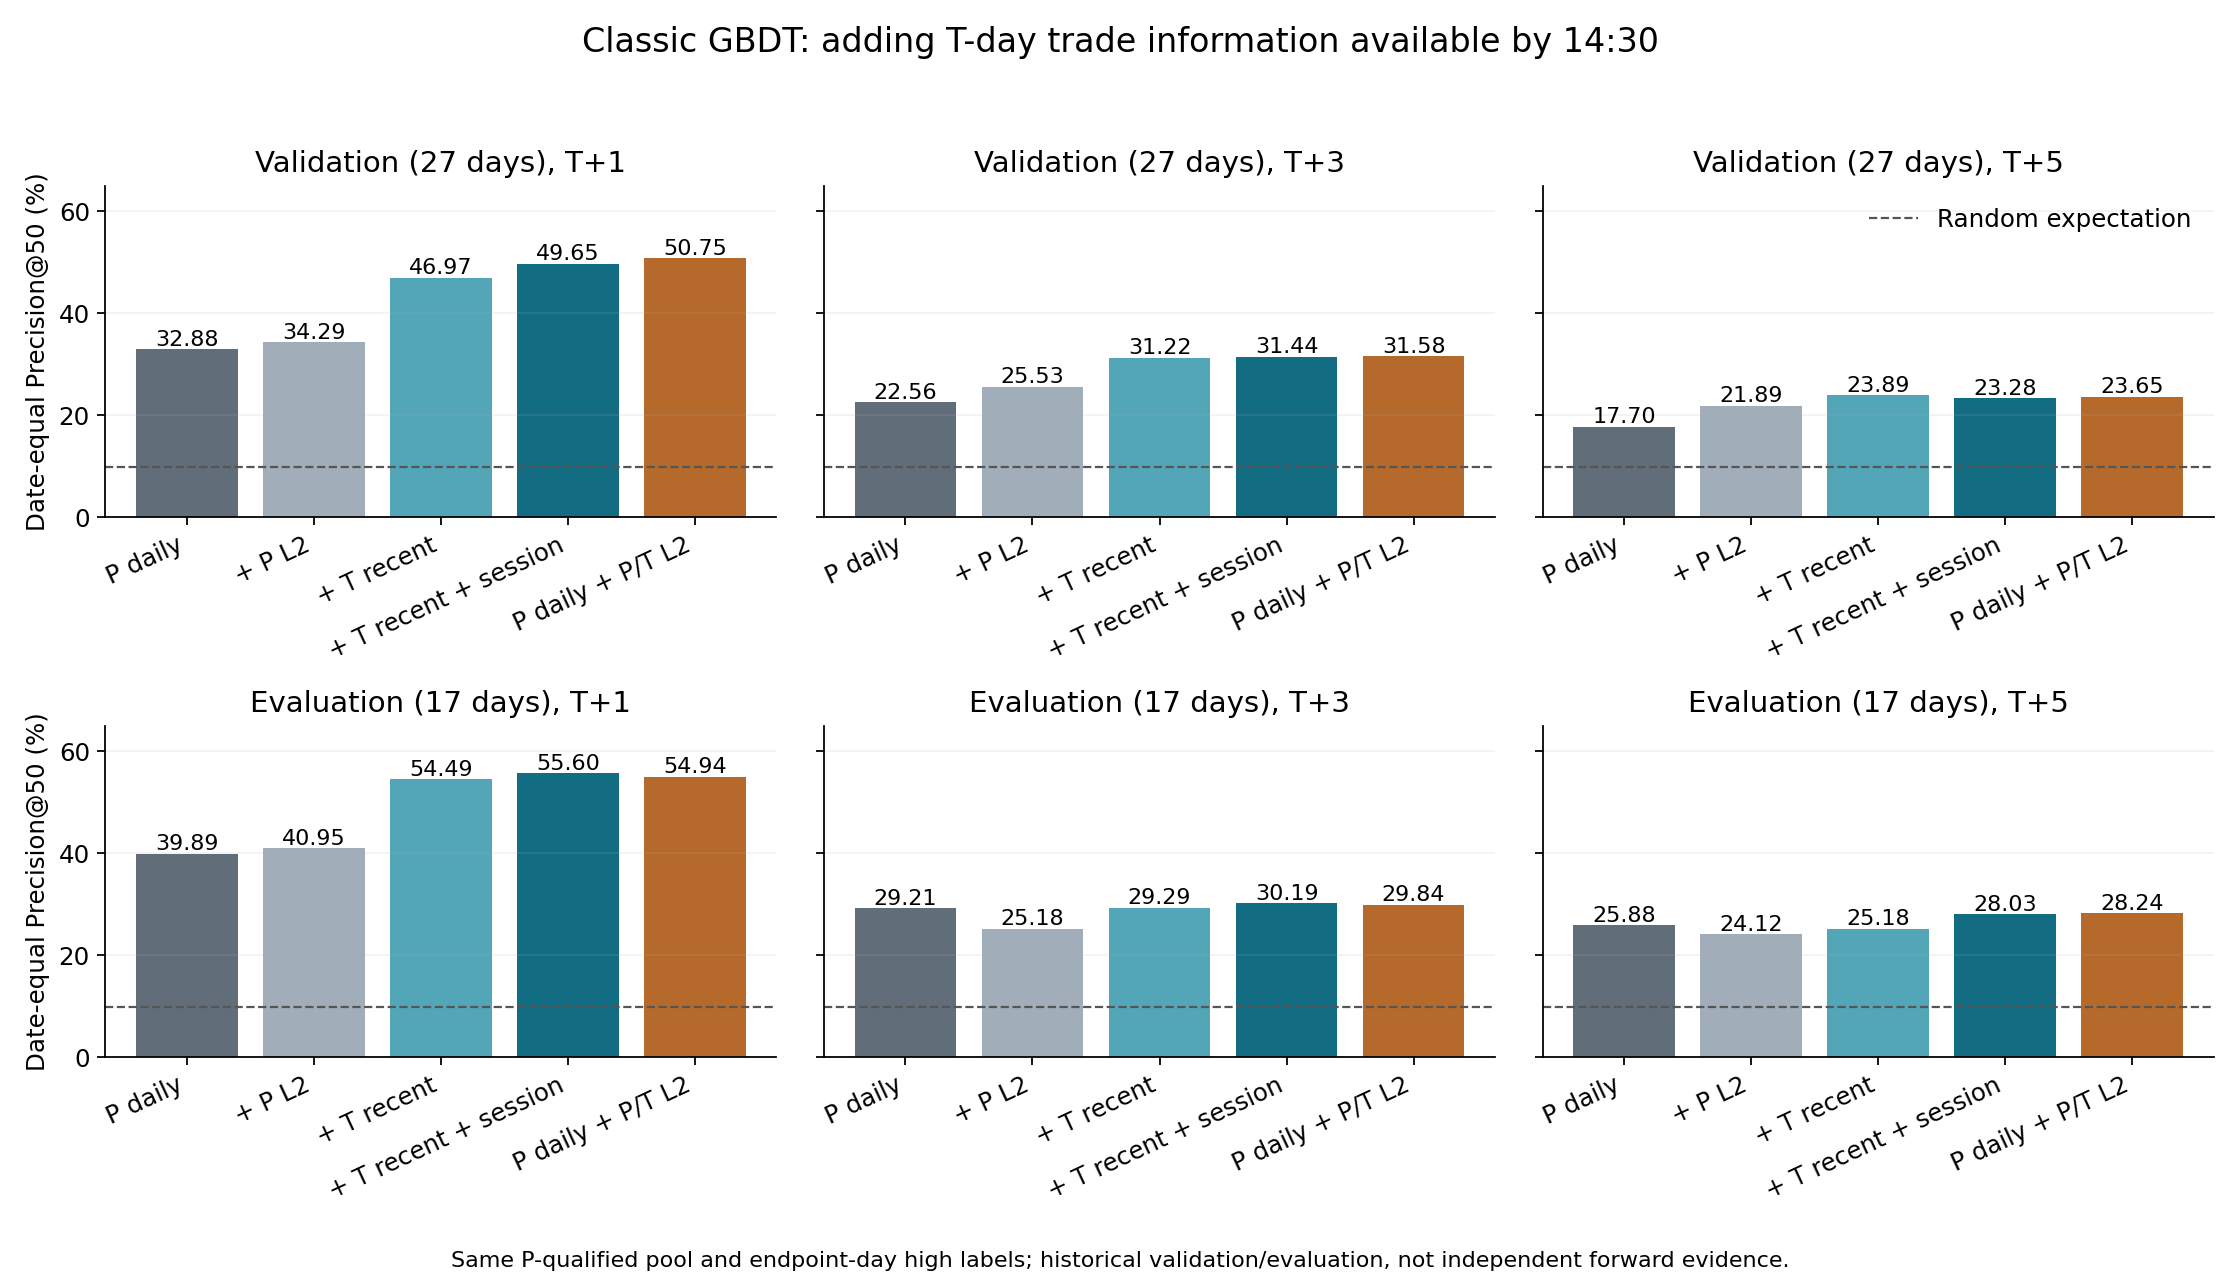

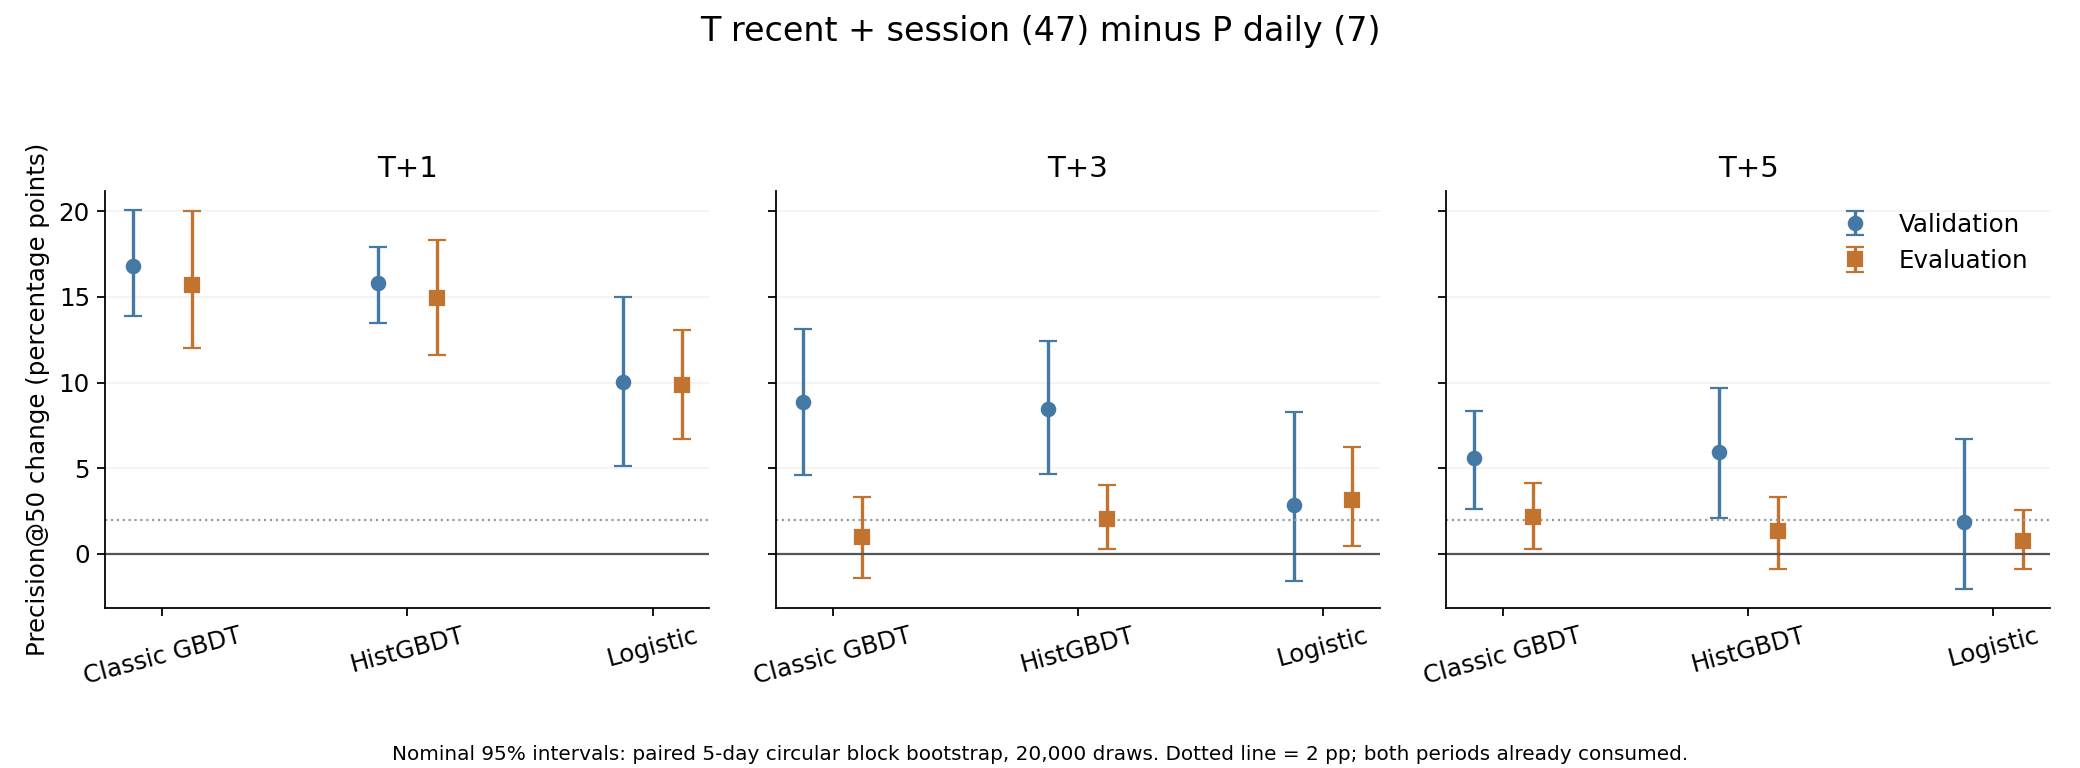

In [9]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':130,'savefig.facecolor':'white'})
group_labels={'daily7':'P daily','previous39':'+ P L2','current39':'+ T recent','current47':'+ T recent + session','combined79':'P daily + P/T L2'}
colors=['#626D7A','#A2ADBA','#53A6B8','#126D83','#B56A2B']
fig,axes=plt.subplots(2,3,figsize=(14,8),sharey=True)
for row,stage in enumerate(protocol['stages']):
    for column,h in enumerate(protocol['horizons']):
        ax=axes[row,column]
        selected=full_summary.loc[full_summary.model.eq('gbdt')&full_summary.stage.eq(stage)&full_summary.horizon.eq(h)].set_index('group').reindex(protocol['features'])
        values=selected.precision.to_numpy()*100
        bars=ax.bar(np.arange(5),values,color=colors)
        ax.axhline(selected.random_precision.iloc[0]*100,color='#555555',ls='--',lw=1,label='Random expectation')
        for bar,value in zip(bars,values):
            if np.isfinite(value):ax.text(bar.get_x()+bar.get_width()/2,value+.7,f'{value:.2f}',ha='center',fontsize=10)
        ax.set_xticks(np.arange(5),list(group_labels.values()),rotation=25,ha='right')
        ax.set_title(f'{stage.title()} ({len(protocol["stages"][stage])} days), T+{h}')
        ax.set_ylim(0,max(55,math.ceil(full_summary.precision.max()*100/10)*10+5))
        ax.grid(axis='y',alpha=.15)
        if column==0:ax.set_ylabel('Date-equal Precision@50 (%)')
        if row==0 and column==2:ax.legend(loc='upper right',frameon=False)
fig.suptitle('Classic GBDT: adding T-day trade information available by 14:30',fontsize=15)
fig.text(.5,.01,'Same P-qualified pool and endpoint-day high labels; historical validation/evaluation, not independent forward evidence.',ha='center',fontsize=10)
fig.tight_layout(rect=[0,.04,1,.95])
fig.savefig(evidence/'figures/gbdt-five-groups.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/gbdt-five-groups.png')))

fig,axes=plt.subplots(1,3,figsize=(13,4.8),sharey=True)
model_labels={'gbdt':'Classic GBDT','hist_gbdt':'HistGBDT','logistic':'Logistic'}
for ax,h in zip(axes,protocol['horizons']):
    for offset,stage,color,marker in [(-.12,'validation','#4579A5','o'),(.12,'evaluation','#C37330','s')]:
        selected=comparison.loc[comparison.horizon.eq(h)&comparison.contrast.eq('current_vs_daily')&comparison.block_sessions.eq(5)&comparison.stage.eq(stage)].set_index('model').reindex(protocol['models'])
        means=selected.mean_difference.to_numpy()*100
        error=np.vstack([means-selected.ci95_lower.to_numpy()*100,selected.ci95_upper.to_numpy()*100-means])
        ax.errorbar(np.arange(3)+offset,means,yerr=error,fmt=marker,color=color,capsize=4,label=stage.title())
    ax.axhline(0,color='#555555',lw=1)
    ax.axhline(2,color='#999999',lw=1,ls=':')
    ax.set_xticks(np.arange(3),list(model_labels.values()),rotation=15)
    ax.set_title(f'T+{h}')
    ax.grid(axis='y',alpha=.15)
axes[0].set_ylabel('Precision@50 change (percentage points)')
axes[-1].legend(frameon=False)
fig.suptitle('T recent + session (47) minus P daily (7)',fontsize=15)
fig.text(.5,.01,'Nominal 95% intervals: paired 5-day circular block bootstrap, 20,000 draws. Dotted line = 2 pp; both periods already consumed.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.07,1,.91])
fig.savefig(evidence/'figures/model-increments.png',dpi=160)
plt.close(fig)
display(Image(filename=str(evidence/'figures/model-increments.png')))

for entry in manifest:
    with (evidence/entry['path']).open('rb') as stream:
        assert hashlib.file_digest(stream,'sha256').hexdigest()==entry['sha256']
for path,entry in source_manifest.items():
    assert hashlib.sha256((evidence/'runtime-source'/path).read_bytes()).hexdigest()==entry['sha256']
verification={'protocol_sha256':protocol_hash,'base_commit':protocol['base_commit'],'legacy_fit_key_sha256':fit_key_hash,'new_decision_fit_key_sha256':new_fit_hash,
    'input_files_unchanged':len(manifest),'source_files_unchanged':len(source_manifest),'feature_days':len(feature_audit),'anchor_outputs_recovered':18,
    'new_fit_outputs':len(new_records),'complete_outputs':sum(r['status'] in ['complete','reused'] for r in fit_records),
    'all_complete_converged':all(r['status'] in ['complete','reused'] for r in fit_records),'metric_days':len(metrics),
    'predictions':int(sum(r.get('prediction_rows',0) for r in fit_records)),'all_saved_scores_replay_exact':all(r.get('replay_exact',False) for r in fit_records),
    'all_selections_independently_recovered':True,'anchor_metrics_exact':True,'future_cutoff_checks':True,'mature_training_labels':True,
    'min_group_stage_coverage':float(full_summary.coverage.min()),'research_only':True}
(evidence/'verification.json').write_text(json.dumps(verification,indent=2)+'\n')
print(verification)